# Task 1: Multi-Class Classification Pipeline (Iris)

**Goal:** build an end-to-end classification pipeline with scikit-learn: load data, explore it, scale features, split 80/20, train two models, and benchmark them with accuracy, precision, recall, F1 and a confusion matrix.

**Dataset:** Iris (150 flowers, 4 measurements, 3 species), loaded from the seaborn-data CSV.

**Models:** Logistic Regression and Decision Tree.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(URL)

print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nClass counts:\n", df["species"].value_counts())
df.head()

Shape: (150, 5)

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory pairplot

A pairplot shows every pair of features, coloured by species. It tells us which features separate the classes well before we train anything.

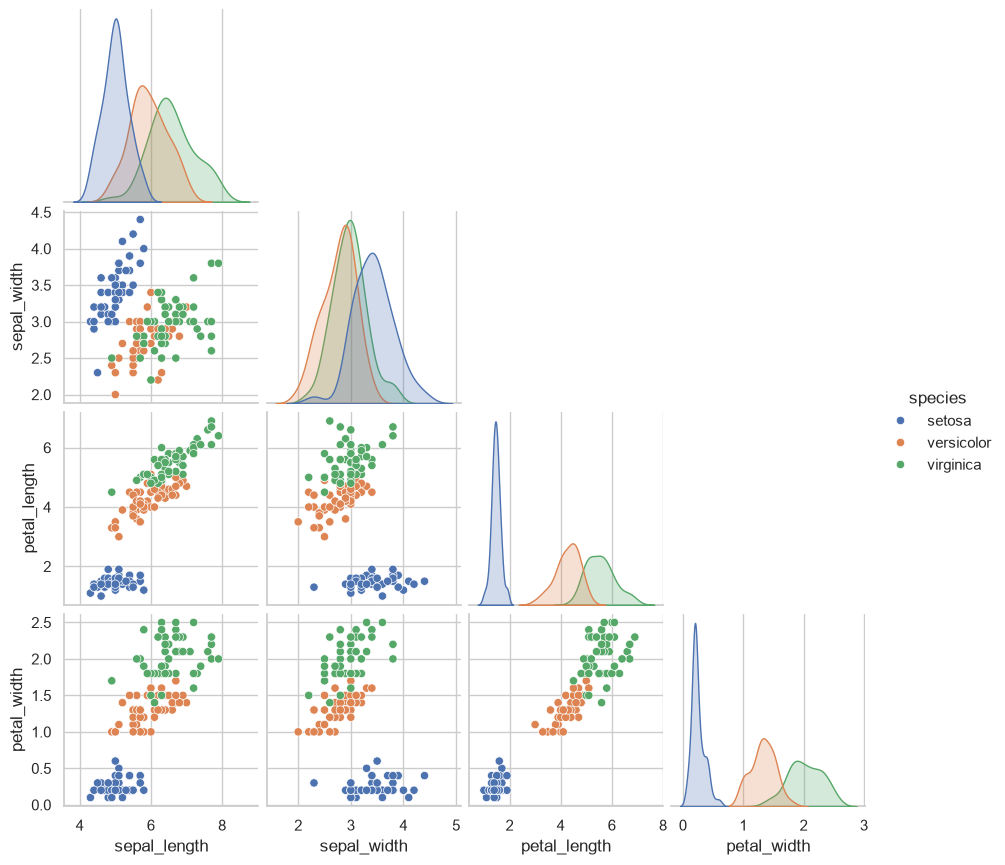

In [3]:
sns.pairplot(df, hue="species", corner=True, height=2.2)
plt.show()

## 4. Train/test split (80/20) and feature scaling

We split first and then fit `StandardScaler` on the **training set only**. Fitting it on all the data would leak information from the test set into training.

In [4]:
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn mean/std from train only
X_test_s = scaler.transform(X_test)         # apply the same transformation to test

# Sanity check: scaled training features should have mean ~0 and std ~1
pd.DataFrame(X_train_s, columns=X.columns).describe().loc[["mean", "std"]].round(2)

Train: (120, 4)  Test: (30, 4)


,sepal_length,sepal_width,petal_length,petal_width
mean,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


## 5. Train the models

The decision tree uses `max_depth=3` to keep it small and readable and to reduce overfitting.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)
print("Both models trained.")

Both models trained.


## 6. Benchmark: accuracy, precision, recall, F1

Precision, recall and F1 are **macro-averaged**: computed per species, then averaged with equal weight.

In [6]:
rows = []
for name, p in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision (macro)": precision_score(y_test, p, average="macro"),
        "Recall (macro)": recall_score(y_test, p, average="macro"),
        "F1 (macro)": f1_score(y_test, p, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.967,0.970,0.967,0.967


In [7]:
for name, p in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, p))

=== Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Decision Tree ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 7. Confusion matrices

Rows are the actual species, columns are the predicted species. Numbers off the diagonal are mistakes.

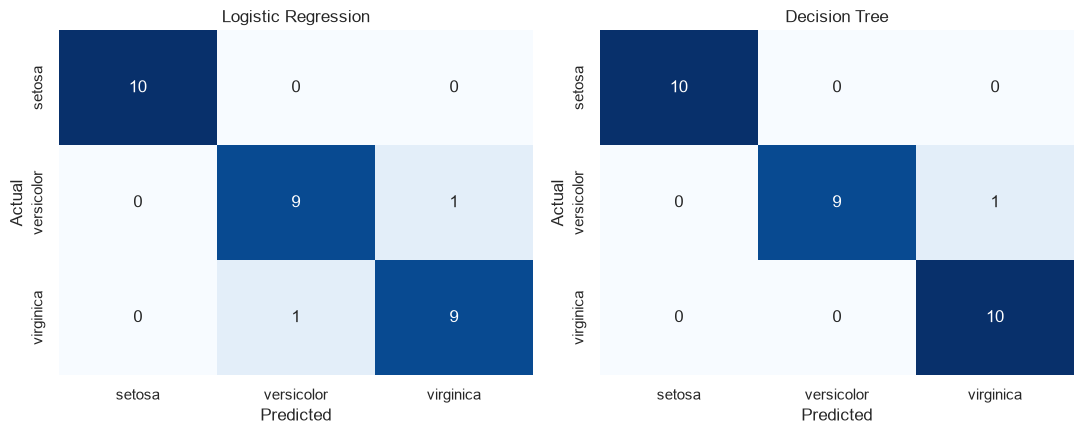

In [8]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 8. Cross-validation check

The test set has only 30 flowers, so one split can be lucky or unlucky. 5-fold cross-validation checks that the accuracy is stable. The scaler sits inside the pipeline, so it is re-fitted on each training fold.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    print(f"{name:20s} mean accuracy = {scores.mean():.3f}  (std {scores.std():.3f})")

Logistic Regression  mean accuracy = 0.953  (std 0.045)
Decision Tree        mean accuracy = 0.960  (std 0.025)


## 9. Decision boundaries

We cannot draw four dimensions, so this plot retrains both models on the two most informative features, petal length and petal width. Dots are the test flowers.

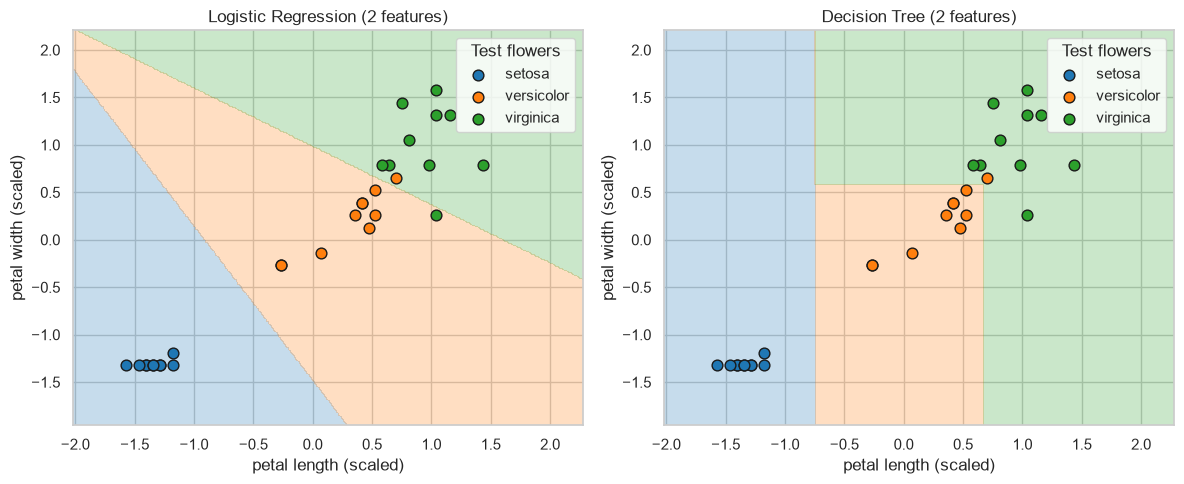

In [10]:
features = ["petal_length", "petal_width"]
le = LabelEncoder()
y_enc = le.fit_transform(y)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    df[features], y_enc, test_size=0.2, stratify=y_enc, random_state=RANDOM_STATE
)
scaler2 = StandardScaler().fit(X2_train)
X2_train_s, X2_test_s = scaler2.transform(X2_train), scaler2.transform(X2_test)

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(X2_train_s, y2_train)
    # Colour every point of a fine grid by the class the model predicts there
    x_min, x_max = X2_train_s[:, 0].min() - 0.5, X2_train_s[:, 0].max() + 0.5
    y_min, y_max = X2_train_s[:, 1].min() - 0.5, X2_train_s[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.25)
    ax.set_xlabel("petal length (scaled)")
    ax.set_ylabel("petal width (scaled)")
    for i, cls in enumerate(le.classes_):
        mask = y2_test == i
        ax.scatter(X2_test_s[mask, 0], X2_test_s[mask, 1], c=colors[i],
                   edgecolor="k", s=60, label=cls)
    ax.set_title(f"{name} (2 features)")
    ax.legend(title="Test flowers")
plt.tight_layout()
plt.show()

## 10. Conclusions

- **Logistic Regression** classified 28 of 30 test flowers correctly (~93.3% accuracy).
- **Decision Tree (max_depth=3)** classified 29 of 30 correctly (~96.7% accuracy).
- **Setosa** was classified perfectly (100%) by both models. It is clearly separable from the other two species.
- **All errors** happened between *versicolor* and *virginica*, whose petal measurements overlap slightly.
- **Decision boundaries:** Logistic Regression draws smooth *linear* boundaries, while the Decision Tree draws *axis-aligned boxes*.
- **Takeaway:** On this small test set the Decision Tree is one flower better, but the difference is tiny. Cross-validation gives a more reliable comparison than a single split.
